In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import numpy as np
from sklearn.metrics import precision_recall_curve,auc,roc_auc_score

In [ ]:
def stat_precision_recal(filename,soft,HLAtype):
    y_test,y_scores=[],[]
    with open(filename) as f:
        for eachline in f:
            
            if "peptide" not in eachline and "measurement_value" not in eachline and HLAtype in eachline:
                line=eachline.strip().split("\t")
                if soft=="LKMHCpan":
                    if len(line[0])>=8 and len(line[0])<=15: #限制肽段长度
                        y_test.append(int(line[-1]))
                        score=float(line[3].split(",")[1].replace("]",""))
                        y_scores.append(score)
            
                elif soft=="NetMHCpan_EL":
                    line=eachline.strip().split()
                    #update后
                    if len(line[4])>=8 and len(line[4])<=15: #限制肽段长度
                        y_test.append(int(line[0]))
                        score=-float(line[14])  
                        y_scores.append(score)
                elif soft=="NetMHCpan_BA":
                    line=eachline.strip().split()
                    if len(line[4])>=8 and len(line[4])<=15: #限制肽段长度
                        y_test.append(int(line[0]))
                        score=-(float(line[17]))   
                        y_scores.append(score)
                elif soft=="MixMHCpred2.2" :
                    line=eachline.strip().split("\t")
                    if len(line[2])>=8 and len(line[2])<=15: #限制肽段长度
                        y_test.append(int(line[0]))
                        score=-(float(line[-1]))
                        y_scores.append(score)
                elif soft=="mhcflurry":
                    line=eachline.strip().split(",")
                    if len(line[0])>=8 and len(line[0])<=15: #限制肽段长度
                        y_test.append(int(line[1]))
                        score=-(round(float(line[5]),3))
                        y_scores.append(score)

    precision,recall,_= precision_recall_curve(y_test, y_scores)
    auc_pr = auc(recall, precision)
    roc_auc = roc_auc_score(y_test, y_scores)
    average_precision = round(average_precision_score(y_test, y_scores),3)    
    average_precision=round(average_precision,2)
    print(f"{soft} {HLAtype} AUC_PR: {auc_pr:.4f} ROC_AUC: {roc_auc:.4f} AP: {average_precision}")
    return  round(auc_pr,2), round(roc_auc,2),precision, recall,average_precision

In [10]:
LKfile="Table_HLAMutant_seq_data_test_expand.predict.format.xls"
netfile="Table_HLAMutant_seq_data_test_expand.tsv-netmhcpna4.1-result.xls"
mhcflurryfile="Table_HLAMutant_seq_data_test_expand-mhcflurry-result.csv"

* HLA-B27:09_C67S

In [11]:
auc_prlk,roc_auclk,precisionlk,recalllk,average_precisionlk=stat_precision_recal(LKfile,"LKMHCpan","HLA-B27:09_C67S")
auc_prEL,roc_aucEL,precisionEL,recallnEL,average_precisionEL=stat_precision_recal(netfile,"NetMHCpan_EL","HLA-B27:09_C67S")
auc_prBA,roc_aucBA,precisionBA,recallBA,average_precisionBA=stat_precision_recal(netfile,"NetMHCpan_BA","HLA-B27:09_C67S")
auc_prmhcflurry,roc_aucmhcflurry,precisionmhcflurry,recallmhcflurry,average_precisionmhcflurry=stat_precision_recal(mhcflurryfile,"mhcflurry","HLA-B27:09")

LKMHCpan HLA-B27:09_C67S AUC_PR: 0.9075 ROC_AUC: 0.9886 AP: 0.91
NetMHCpan_EL HLA-B27:09_C67S AUC_PR: 0.6885 ROC_AUC: 0.8952 AP: 0.69
NetMHCpan_BA HLA-B27:09_C67S AUC_PR: 0.5606 ROC_AUC: 0.8633 AP: 0.56
mhcflurry HLA-B27:09 AUC_PR: 0.7767 ROC_AUC: 0.9460 AP: 0.78


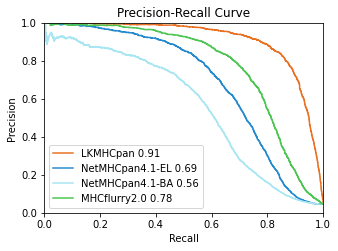

In [ ]:
# 绘制PR曲线
plt.figure(figsize=(5, 3.5)) 
plt.step(recalllk, precisionlk, where='post', label='LKMHCpan '+str(auc_prlk),color="#E97123") # AP: {average_precisionlk:.2f}') #Average Precision
plt.step(recallnEL, precisionEL, where='post', label='NetMHCpan4.1-EL '+str(auc_prEL),color="#248ACE")# AP: {average_precisionnet:.2f}')
plt.step(recallBA, precisionBA, where='post', label='NetMHCpan4.1-BA '+str(auc_prBA),color="#A8E6F1")# AP: {average_precisionnet:.2f}')
plt.step(recallmhcflurry, precisionmhcflurry, where='post', label='MHCflurry2.1.0 '+str(auc_prmhcflurry),color="#4CC552")# AP: {average_precisionmhcflurry:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.0])
plt.xlim([0.0, 1.0])
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.savefig("PRAUC_of_each_software_HLAmutation_HLAB2709.svg")
plt.show()

* HLA-B27:05_C67S

In [13]:
auc_prlk,roc_auclk,precisionlk,recalllk,average_precisionlk=stat_precision_recal(LKfile,"LKMHCpan","HLA-B27:05_C67S")
auc_prEL,roc_aucEL,precisionEL,recallnEL,average_precisionEL=stat_precision_recal(netfile,"NetMHCpan_EL","HLA-B27:05_C67S")
auc_prBA,roc_aucBA,precisionBA,recallBA,average_precisionBA=stat_precision_recal(netfile,"NetMHCpan_BA","HLA-B27:05_C67S")
auc_prmhcflurry,roc_aucmhcflurry,precisionmhcflurry,recallmhcflurry,average_precisionmhcflurry=stat_precision_recal(mhcflurryfile,"mhcflurry","HLA-B27:05")

LKMHCpan HLA-B27:05_C67S AUC_PR: 0.7945 ROC_AUC: 0.9681 AP: 0.8
NetMHCpan_EL HLA-B27:05_C67S AUC_PR: 0.5047 ROC_AUC: 0.8178 AP: 0.5
NetMHCpan_BA HLA-B27:05_C67S AUC_PR: 0.3965 ROC_AUC: 0.7576 AP: 0.4
mhcflurry HLA-B27:05 AUC_PR: 0.6341 ROC_AUC: 0.9165 AP: 0.63


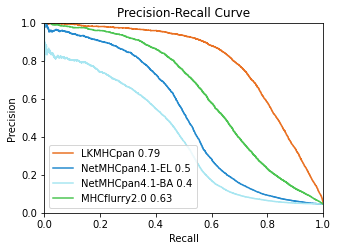

In [14]:
# 绘制PR曲线
plt.figure(figsize=(5, 3.5)) 
plt.step(recalllk, precisionlk, where='post', label='LKMHCpan '+str(auc_prlk),color="#E97123") # AP: {average_precisionlk:.2f}') #Average Precision
plt.step(recallnEL, precisionEL, where='post', label='NetMHCpan4.1-EL '+str(auc_prEL),color="#248ACE")# AP: {average_precisionnet:.2f}')
plt.step(recallBA, precisionBA, where='post', label='NetMHCpan4.1-BA '+str(auc_prBA),color="#A8E6F1")# AP: {average_precisionnet:.2f}')
plt.step(recallmhcflurry, precisionmhcflurry, where='post', label='MHCflurry2.0 '+str(auc_prmhcflurry),color="#4CC552")# AP: {average_precisionmhcflurry:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.0])
plt.xlim([0.0, 1.0])
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.savefig("PRAUC_of_each_software_HLAmutation_HLAB2705.svg")
plt.show()